# 01 — Select glaciers from GLIMS

**Purpose.** First stage of the pipeline. Narrows the full GLIMS inventory to the ~18k glaciers
GlacierView pulls Landsat imagery for, and writes each glacier's outline and padded bounding box for
the Earth Engine pull notebooks (03–05). The rules live in `glacierview.glims.select_glaciers`:

1. Keep outlines drawn after 2005-01-01.
2. Drop the catch-all regional centres: Svalbard, Jan Mayen and Bouvet; Various (GlobGlacier); the
   Randolph Glacier Inventory umbrella; Antarctic Peninsula; Various (NSIDC).
3. Keep glaciers between 1 and 50 km². The bounds are a judgement call to get typical glaciers:
   nothing tiny, nothing unusually large.
4. Where GLIMS has several outlines for one glacier, keep the first.
5. Add `bboxes`: the outline's envelope scaled 1.1×, as a string of (lon, lat) corners.

## Inputs
- **GLIMS polygon shapefile**, 2021-09-14 snapshot, at `config.glims_inventory_path()`
  (`src/glims/data/glims_db_20210914/glims_polygons.shp`). Downloaded from the NSIDC GLIMS database;
  gitignored, so a fresh clone needs it re-downloaded.
- **Environment**: the project's uv environment as the kernel. No credentials needed.

## Outputs
- `config.glims_selection_path()` (`src/glims/data/training_samples/glims_18k_bb.shp`): read by
  notebook 02 and the Earth Engine notebooks 03–05.
- `figures/distribution_of_glacier_surface_area.jpg` (tracked).
- `glaciers_per_geog_area.csv` in `config.glims_data_dir()`: unique glaciers per GLIMS region,
  before filtering.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from glacierview import config, glims, log

log.configure()
plt.style.use(config.mpl_style())
inventory = glims.read_inventory()

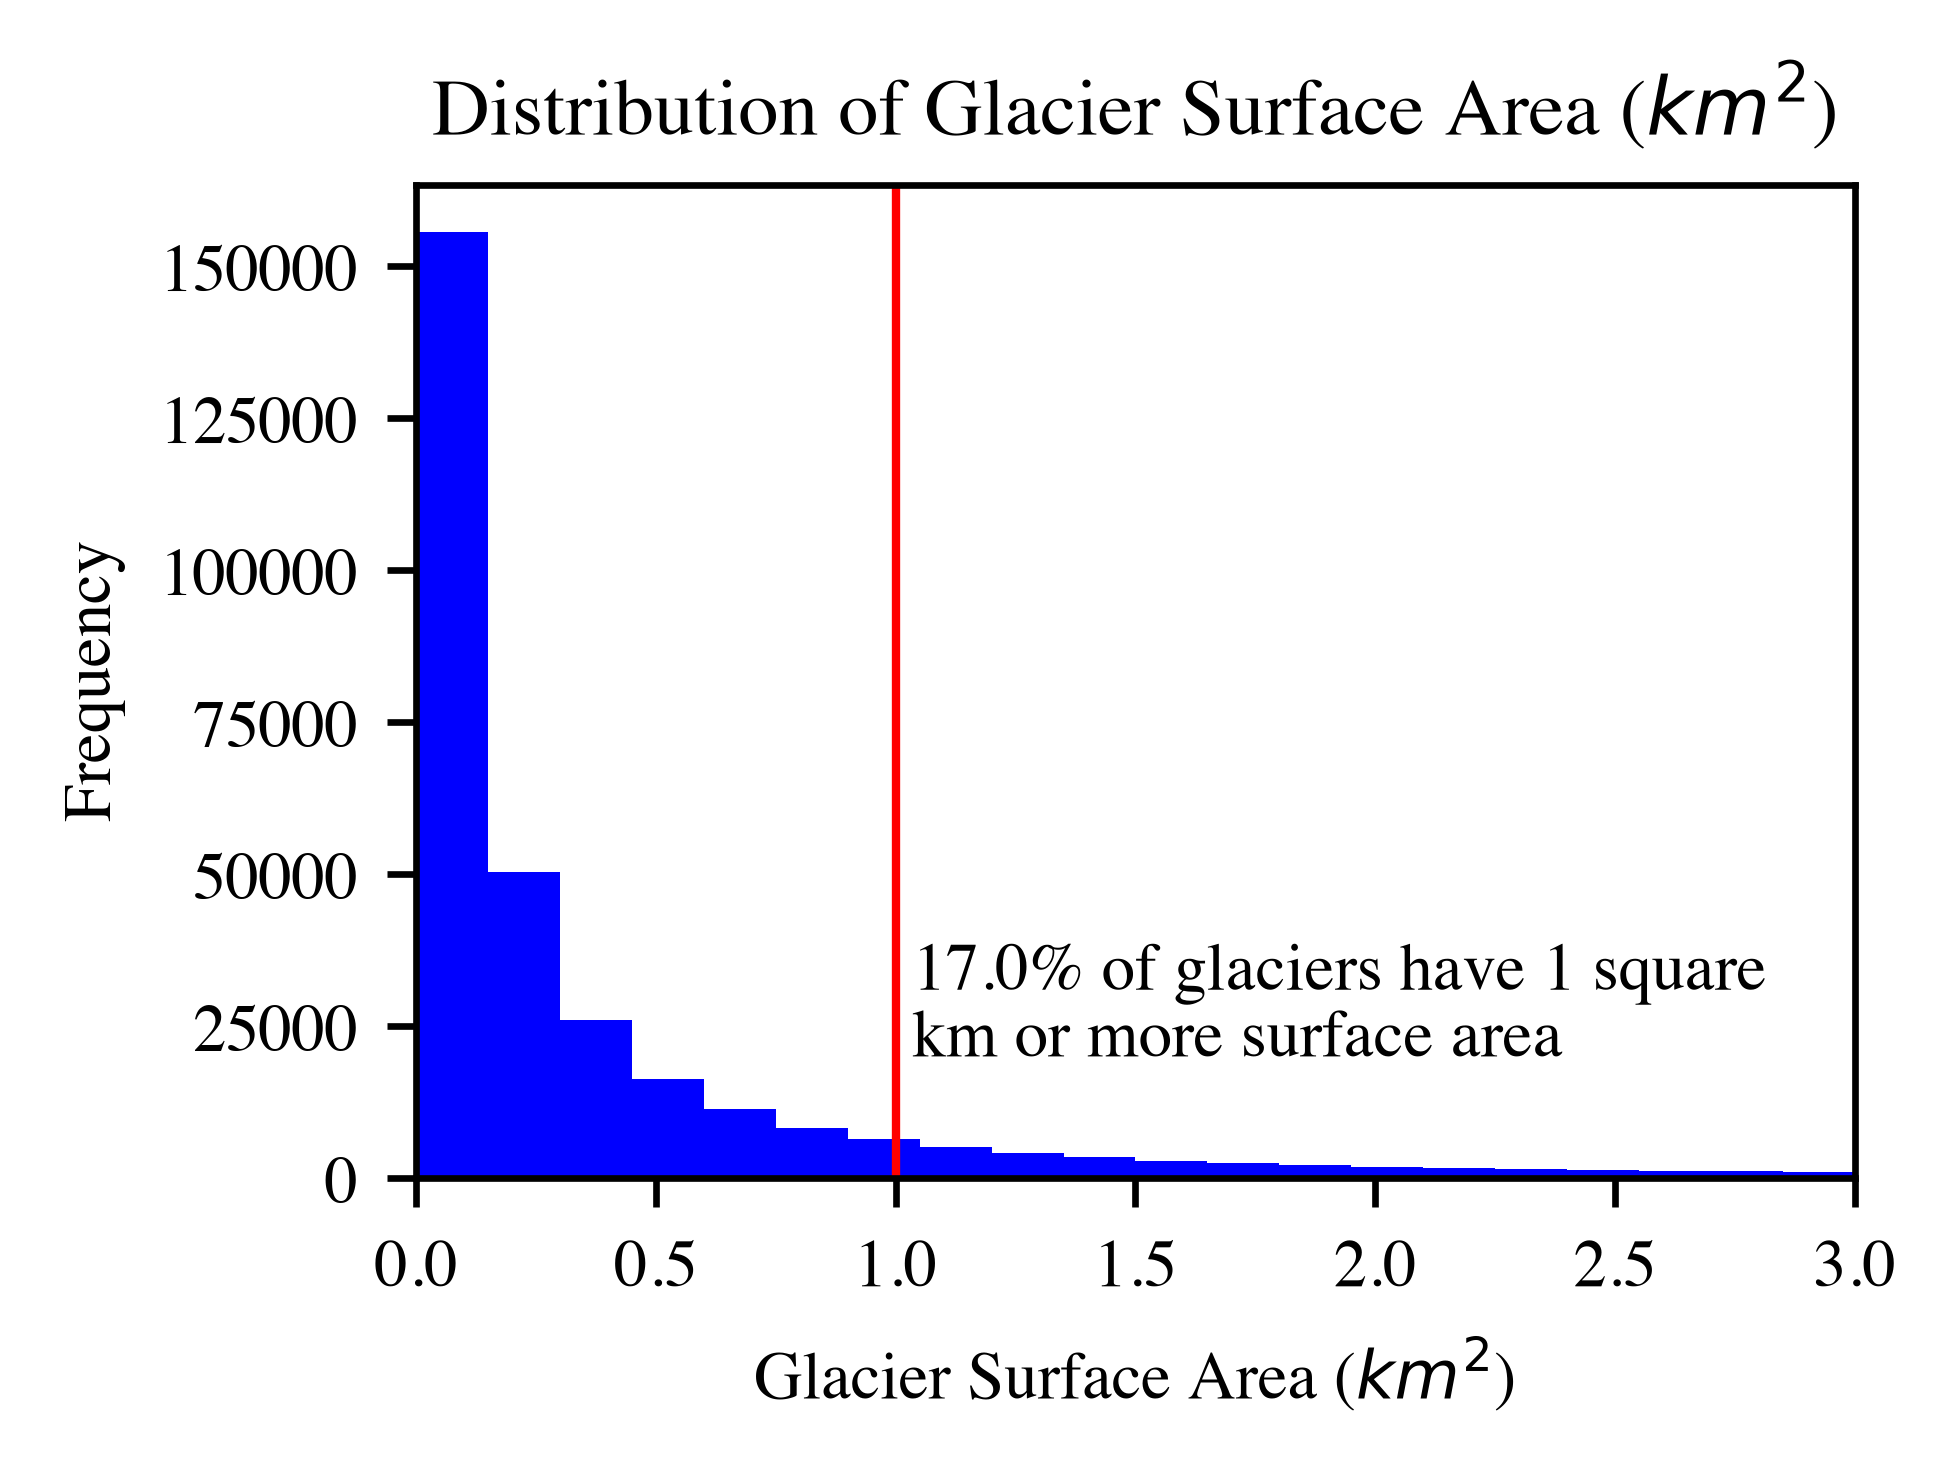

In [2]:
areas = inventory.groupby("glac_id")["db_area"].max()

fig, ax = plt.subplots()
ax.hist(areas, bins=np.arange(0, 50, 0.15))
ax.axvline(1, color="red")
share = (areas > 1).mean()
ax.text(1.0, 20_000, f" {share:.1%} of glaciers have 1 square \n km or more surface area")
ax.set(xlim=(0, 3), xlabel="Glacier Surface Area ($km^2$)", ylabel="Frequency",
       title="Distribution of Glacier Surface Area ($km^2$)")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "distribution_of_glacier_surface_area.jpg", dpi=600)

In [3]:
per_region = inventory.groupby("geog_area")["glac_id"].nunique()
per_region.to_csv(config.glims_data_dir() / "glaciers_per_geog_area.csv")

In [4]:
glaciers = glims.add_bounding_boxes(glims.select_glaciers(inventory))
glims.write_selection(glaciers);

2026-10-23 17:11:46,118 INFO    glacierview.glims | 328115 glaciers in the inventory


2026-10-23 17:11:46,244 INFO    glacierview.glims | 170363 outlined after 2005-01-01


2026-10-23 17:11:46,282 INFO    glacierview.glims | 122212 not a catch-all region


2026-10-23 17:11:46,294 INFO    glacierview.glims | 18093 1-50 km^2


2026-10-23 17:11:48,191 INFO    pyogrio._io | Created 18,093 records


2026-10-23 17:11:48,239 INFO    glacierview.glims | wrote 18093 glaciers to /Users/mattw/Desktop/projects/GlacierView/src/glims/data/training_samples/glims_18k_bb.shp
